In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
# Data Preparation
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv'
!wget $data

--2026-10-05 11:05:40--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1475504 (1.4M) [text/plain]
Saving to: ‘data.csv.3’

data.csv.3          100%[===================>]   1.41M  --.-KB/s    in 0.01s   

2026-10-05 11:05:40 (131 MB/s) - ‘data.csv.3’ saved [1475504/1475504]



In [3]:
df = pd.read_csv('data.csv', engine='python', on_bad_lines='skip')
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
df.dtypes # how to change dtype?
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [6]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [7]:
# EDA (Exploratory Data Analysis)
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())


make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48
model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914
year
[2011 2012 2013 1992 1993]
28
engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10
engine_hp
[335. 300. 230. 320. 172.]
356
engine_cylinders
[ 6.  4.  5.  8. 12.]
9
transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5
driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4
number_of_doors
[ 2.  4.  3. nan]
3
market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-performance

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

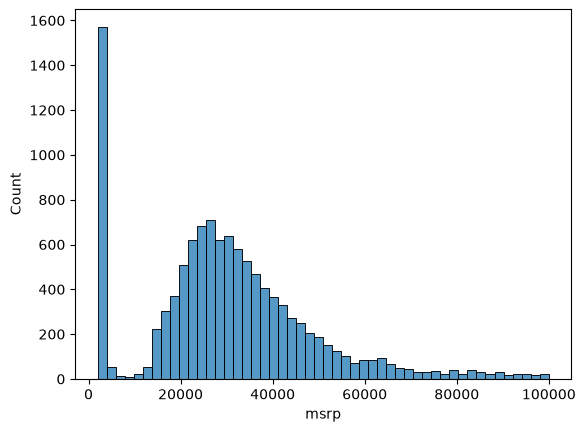

In [9]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50)

In [10]:
# np.log([0+1, 2, 11, 1001, 100001])
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

<Axes: xlabel='msrp', ylabel='Count'>

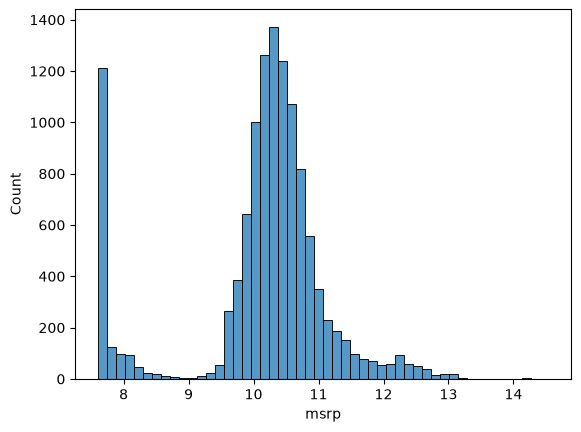

In [11]:
price_logs = np.log1p(df.msrp)
sns.histplot(price_logs, bins=50)

In [12]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [13]:
# Setting up validation framework
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = int(n * 0.6)
n, n_val+n_test+n_train

(11914, 11912)

In [14]:
n_train = n - n_val - n_test
df.iloc[[0, 1, 2]]
df.iloc[10:20]
df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

In [15]:
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [16]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3995,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,NaN,large,4dr_suv,18,13,549,29695
7474,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,38,25,873,30495
7300,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,28,19,2202,37650
3148,chevrolet,cruze,2015,regular_unleaded,138.0,4.0,manual,front_wheel_drive,4.0,NaN,midsize,sedan,36,25,1385,16170
747,volvo,740,1991,regular_unleaded,162.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",midsize,sedan,20,17,870,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10845,mazda,truck,2003,regular_unleaded,207.0,6.0,manual,four_wheel_drive,2.0,NaN,compact,extended_cab_pickup,17,14,586,19975
4861,kia,forte,2015,regular_unleaded,201.0,4.0,manual,front_wheel_drive,4.0,"hatchback,performance",compact,4dr_hatchback,29,21,1720,20890
2334,dodge,caravan,2006,regular_unleaded,150.0,4.0,automatic,front_wheel_drive,4.0,flex_fuel,large,passenger_minivan,24,17,1851,18630
8651,acura,rsx,2005,regular_unleaded,160.0,4.0,automatic,front_wheel_drive,2.0,"hatchback,luxury,performance",compact,2dr_hatchback,31,22,204,21175


In [17]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,gmc,envoy_xl,2005,regular_unleaded,275.0,6.0,automatic,rear_wheel_drive,4.0,NaN,large,4dr_suv,18,13,549,29695
1,volkswagen,passat,2016,regular_unleaded,170.0,4.0,automatic,front_wheel_drive,4.0,NaN,midsize,sedan,38,25,873,30495
2,honda,odyssey,2016,regular_unleaded,248.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,28,19,2202,37650
3,chevrolet,cruze,2015,regular_unleaded,138.0,4.0,manual,front_wheel_drive,4.0,NaN,midsize,sedan,36,25,1385,16170
4,volvo,740,1991,regular_unleaded,162.0,4.0,automatic,rear_wheel_drive,4.0,"luxury,performance",midsize,sedan,20,17,870,2000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,mazda,truck,2003,regular_unleaded,207.0,6.0,manual,four_wheel_drive,2.0,NaN,compact,extended_cab_pickup,17,14,586,19975
7146,kia,forte,2015,regular_unleaded,201.0,4.0,manual,front_wheel_drive,4.0,"hatchback,performance",compact,4dr_hatchback,29,21,1720,20890
7147,dodge,caravan,2006,regular_unleaded,150.0,4.0,automatic,front_wheel_drive,4.0,flex_fuel,large,passenger_minivan,24,17,1851,18630
7148,acura,rsx,2005,regular_unleaded,160.0,4.0,automatic,front_wheel_drive,2.0,"hatchback,luxury,performance",compact,2dr_hatchback,31,22,204,21175


In [18]:
y_train = np.log1p(df_train.msrp.values)
print(len(y_train))
y_test = np.log1p(df_test.msrp.values)
print(len(y_test))
y_val = np.log1p(df_val.msrp.values)
print(len(y_val))

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

7150
2382
2382


In [19]:
print(len(df))
len(y_val)+len(y_test)+len(y_train)

11914


11914

In [20]:
# Linear Regression
df_train.iloc[10]

make                            toyota
model                            yaris
year                              2015
engine_fuel_type      regular_unleaded
engine_hp                        106.0
engine_cylinders                   4.0
transmission_type               manual
driven_wheels        front_wheel_drive
number_of_doors                    2.0
market_category              hatchback
vehicle_size                   compact
vehicle_style            2dr_hatchback
highway_mpg                         37
city_mpg                            30
popularity                        2031
Name: 10, dtype: object

In [21]:
def linear_regression(xi):
    n = len(xi)
    pred = w0
    for j in range(n):
        pred += w[j] * xi[j]
    return pred
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

linear_regression(xi)
# prediction = np.expm1(12.312)

12.312

In [22]:
# Linear Regression vector form
def dot(xi, w):
    n = len(xi)
    res = 0.0
    for j in range(n):
        res += xi[j] + w[j]
    return res

x1 = [1, 148, 24, 1385]
x2 = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)

In [23]:
def linear_regression(xi):
    xi = [1] + xi
    return dot(xi, w_new)

In [24]:
# Training linear regression model
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38, 24, 185],
    [142, 25, 431],
    [453, 31, 86],
]
# X = np.array(X)
# ones = np.ones(X.shape[0])
# X = np.column_stack([ones, X])

# print(ones)
# print(X)

# XTX =X.T.dot(X)
# XTX_inv = np.linalg.inv(XTX)

# XTX.dot(XTX_inv)

In [25]:
# XTX.dot(np.linalg.inv(XTX))

In [26]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]
# w_full = XTX_inv.dot(X.T).dot(y)
# w0 = w_full[0]
# w = w_full[1:]

In [48]:
# Baseline model
df_train.dtypes
def train_linear_regression(X, y):

    X = np.array(X)
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    print(f"X: {X}")
    XTX =X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    print(w_full)
    return w_full[0], w_full[1:]

train_linear_regression(X, y)

X: [[1.000e+00 1.480e+02 2.400e+01 1.385e+03]
 [1.000e+00 1.320e+02 2.500e+01 2.031e+03]
 [1.000e+00 4.530e+02 1.100e+01 8.600e+01]
 [1.000e+00 1.580e+02 2.400e+01 1.850e+02]
 [1.000e+00 1.720e+02 2.500e+01 2.010e+02]
 [1.000e+00 4.130e+02 1.100e+01 8.600e+01]
 [1.000e+00 3.800e+01 2.400e+01 1.850e+02]
 [1.000e+00 1.420e+02 2.500e+01 4.310e+02]
 [1.000e+00 4.530e+02 3.100e+01 8.600e+01]]
[ 2.52375992e+02 -1.17624462e-01 -2.36784745e+00 -6.36108796e-03]


(np.float64(252.37599202446552),
 array([-0.11762446, -2.36784745, -0.00636109]))

In [28]:
# base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
# x_train = df_train[base].values
# x_train = df_train[base].fillna(0).values
# w0, w = train_linear_regression(x_train, y_train)
# y_pred = w0 + x_train.dot(w)

In [29]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

NameError: name 'y_pred' is not defined

In [30]:
# RMSE
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)
# rmse(y_train, y_pred)

In [31]:
# Validating Model
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
x_train = df_train[base].values
x_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(x_train, y_train)
y_pred = w0 + x_train.dot(w)

def prepare_x(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    x = df_num.values
    return x

x_train = prepare_x(df_train)
w0, w = train_linear_regression(x_train, y_train)

x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

[[1.000e+00 2.750e+02 6.000e+00 1.800e+01 1.300e+01 5.490e+02]
 [1.000e+00 1.700e+02 4.000e+00 3.800e+01 2.500e+01 8.730e+02]
 [1.000e+00 2.480e+02 6.000e+00 2.800e+01 1.900e+01 2.202e+03]
 ...
 [1.000e+00 1.500e+02 4.000e+00 2.400e+01 1.700e+01 1.851e+03]
 [1.000e+00 1.600e+02 4.000e+00 3.100e+01 2.200e+01 2.040e+02]
 [1.000e+00 2.740e+02 4.000e+00 2.700e+01 1.700e+01 1.439e+03]]
[ 7.90489462e+00  9.35338298e-03 -1.38236607e-01  1.49631207e-02
  1.51021128e-02 -1.97546303e-05]
[[1.000e+00 2.750e+02 6.000e+00 1.800e+01 1.300e+01 5.490e+02]
 [1.000e+00 1.700e+02 4.000e+00 3.800e+01 2.500e+01 8.730e+02]
 [1.000e+00 2.480e+02 6.000e+00 2.800e+01 1.900e+01 2.202e+03]
 ...
 [1.000e+00 1.500e+02 4.000e+00 2.400e+01 1.700e+01 1.851e+03]
 [1.000e+00 1.600e+02 4.000e+00 3.100e+01 2.200e+01 2.040e+02]
 [1.000e+00 2.740e+02 4.000e+00 2.700e+01 1.700e+01 1.439e+03]]
[ 7.90489462e+00  9.35338298e-03 -1.38236607e-01  1.49631207e-02
  1.51021128e-02 -1.97546303e-05]


np.float64(0.7398184285113428)

In [32]:
# simple feature engineering
2026 - df_train.year #.max

0       21
1       10
2       10
3       11
4       35
        ..
7145    23
7146    11
7147    20
7148    21
7149    12
Name: year, Length: 7150, dtype: int64

In [43]:
def prepare_x(df):
    df = df.copy()
    df['age'] = 2026 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values

    del df['age']
    return x

x_train = prepare_x(df_train)
print(x_train)
w0, w = train_linear_regression(x_train, y_train)

x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

[[ 275.    6.   18.   13.  549.   21.]
 [ 170.    4.   38.   25.  873.   10.]
 [ 248.    6.   28.   19. 2202.   10.]
 ...
 [ 150.    4.   24.   17. 1851.   20.]
 [ 160.    4.   31.   22.  204.   21.]
 [ 274.    4.   27.   17. 1439.   12.]]
[[1.000e+00 2.750e+02 6.000e+00 ... 1.300e+01 5.490e+02 2.100e+01]
 [1.000e+00 1.700e+02 4.000e+00 ... 2.500e+01 8.730e+02 1.000e+01]
 [1.000e+00 2.480e+02 6.000e+00 ... 1.900e+01 2.202e+03 1.000e+01]
 ...
 [1.000e+00 1.500e+02 4.000e+00 ... 1.700e+01 1.851e+03 2.000e+01]
 [1.000e+00 1.600e+02 4.000e+00 ... 2.200e+01 2.040e+02 2.100e+01]
 [1.000e+00 2.740e+02 4.000e+00 ... 1.700e+01 1.439e+03 1.200e+01]]
[ 1.01164953e+01  3.67470153e-03  8.43968744e-02 -3.50116180e-03
  1.25655778e-02 -5.33182582e-05 -9.35472614e-02]


np.float64(0.5133241025826414)

In [58]:
# Categorical variables
makes = list(df.make.value_counts().head().index)
makes

['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']

In [56]:
df_train.number_of_doors.unique()
df_train.make.value_counts()

make
chevrolet        672
ford             518
volkswagen       468
toyota           450
dodge            354
nissan           352
gmc              326
honda            282
mazda            247
cadillac         237
suzuki           222
mercedes-benz    216
infiniti         196
audi             189
bmw              186
hyundai          180
volvo            161
subaru           155
acura            152
kia              136
mitsubishi       127
lexus            124
buick            115
chrysler         114
pontiac          114
lincoln          106
oldsmobile        93
land_rover        89
porsche           71
saab              67
aston_martin      60
plymouth          50
bentley           47
ferrari           44
fiat              40
scion             40
maserati          38
lamborghini       30
rolls-royce       20
lotus             18
tesla             12
hummer            11
maybach            9
alfa_romeo         4
mclaren            3
genesis            2
spyker             2
bugatti 

In [59]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df_train['num_doors_%s' % v] = (df_train.number_of_doors == v).astype('int')
    # del df_train['num_doors_4']

    for v in makes:
        df['make_%s' % v] = (df.make == v).astype('int')
        features.append('make_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values

    print(df_num.head())

    # del df['age']
    return x

x_train = prepare_x(df_train)
print(x_train)
print(x_train.size, y_train.size)

w0, w = train_linear_regression(x_train, y_train)

x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

   engine_hp  engine_cylinders  highway_mpg  city_mpg  popularity  age  \
0      275.0               6.0           18        13         549   12   
1      170.0               4.0           38        25         873    1   
2      248.0               6.0           28        19        2202    1   
3      138.0               4.0           36        25        1385    2   
4      162.0               4.0           20        17         870   26   

   make_chevrolet  make_ford  make_volkswagen  make_toyota  make_dodge  
0               0          0                0            0           0  
1               0          0                1            0           0  
2               0          0                0            0           0  
3               1          0                0            0           0  
4               0          0                0            0           0  
[[275.   6.  18. ...   0.   0.   0.]
 [170.   4.  38. ...   1.   0.   0.]
 [248.   6.  28. ...   0.   0.   0.]
 ...
 

np.float64(0.5041893841142805)

In [60]:
df_train.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
num_doors_2            int64
num_doors_3            int64
num_doors_4            int64
dtype: object

In [62]:
categories_var = ['make','model', 'engine_fuel_type','transmission_type','driven_wheels','market_category','vehicle_size','vehicle_style']

In [63]:
categories = {}

for c in categories_var:
    categories[c] = list(df[c].value_counts().head().index)

categories

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'model': ['silverado_1500',
  'tundra',
  'f-150',
  'sierra_1500',
  'beetle_convertible'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'luxury,performance',
  'hatchback'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [67]:
def prepare_x(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df_train['num_doors_%s' % v] = (df_train.number_of_doors == v).astype('int')
    # del df_train['num_doors_4']

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    x = df_num.values

    # print(df_num.head())

    # del df['age']
    return x

x_train = prepare_x(df_train)
# print(x_train)
# print(x_train.size, y_train.size)
w0, w = train_linear_regression(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred) # MASSIVE

X: [[  1. 275.   6. ...   0.   0.   0.]
 [  1. 170.   4. ...   0.   0.   0.]
 [  1. 248.   6. ...   0.   0.   0.]
 ...
 [  1. 150.   4. ...   0.   0.   0.]
 [  1. 160.   4. ...   0.   0.   0.]
 [  1. 274.   4. ...   1.   0.   0.]]
[-6.24683687e+16 -8.06551651e-01 -6.68065567e+01 -3.55554945e+00
 -5.53810800e+01 -8.37753384e-03 -1.76664237e+01 -2.84509898e+01
 -1.57863303e+01 -8.26003604e+01  8.83113630e+01 -6.81218715e+01
  6.90707028e+01 -1.86767299e+02  1.05482096e+02  8.35915660e+00
 -6.59284833e+01  3.18417415e+02  3.21613301e+02  2.66381352e+02
  2.39390420e+02  5.60832626e+02  7.85357158e+16  7.85357158e+16
  7.85357158e+16  7.85357158e+16  7.85357158e+16 -1.60673471e+16
 -1.60673471e+16 -1.60673471e+16 -1.60673471e+16 -1.63419190e+02
 -5.79108581e+01 -2.54899263e+01  9.70950193e+00  5.40797008e+01
 -8.50106431e+01 -1.18941425e+02 -8.02927327e+01  2.89314970e-03
  7.13129152e-02  7.22269023e-02  2.29017540e-01 -6.89462805e-02]


np.float64(237.4771923516635)

In [69]:
# Regularization
X = [
    [4, 4, 4],
    [3, 5, 5],
    [5, 1, 1],
    [5, 4, 4],
    [7, 5, 5],
    [4, 5, 5],
]

X = np.array(X)
X.T.dot(X) # singular -- solve by adding a small value to the matrix

array([[140, 111, 111],
       [111, 108, 108],
       [111, 108, 108]])

In [75]:
XTX = [
    [1, 2, 2],
    [2, 1, 1.0000001],
    [2, 1.0000001, 1]
]
XTX = np.array(XTX)
print(np.linalg.inv(XTX))

XTX += 0.01*np.eye(3)
print()
print(np.linalg.inv(XTX))

[[-3.33333356e-01  3.33333339e-01  3.33333339e-01]
 [ 3.33333339e-01 -5.00000008e+06  4.99999991e+06]
 [ 3.33333339e-01  4.99999991e+06 -5.00000008e+06]]

[[ -0.33668908   0.33501399   0.33501399]
 [  0.33501399  49.91590897 -50.08509104]
 [  0.33501399 -50.08509104  49.91590897]]


In [77]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX += r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

x_train = prepare_x(df_train)
# print(x_train)
# print(x_train.size, y_train.size)
w0, w = train_linear_regression_reg(x_train, y_train)
x_val = prepare_x(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred) # MASSIVE

np.float64(0.4541698060976237)

In [82]:
# Tuning model

for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    
    x_train = prepare_x(df_train)
    w0, w = train_linear_regression_reg(x_train, y_train, r=r)
    x_val = prepare_x(df_val)
    y_pred = w0 + x_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)


0.0 -6.246836867605392e+16 237.4771923516635
1e-05 5.77265371544713 0.4541702265808992
0.0001 5.991888187137887 0.454170187049833
0.001 5.96575461275236 0.4541698060976237
0.1 5.947761306451979 0.4541318478809656
1 5.794049134891836 0.4541188136930567
10 4.832191770094418 0.4660803012451658


In [93]:
# Using the model
# train/val/test
df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
X_full_train = prepare_x(df_full_train)
# df_full_train.tail()
# df_full_train['num_doors_2'].unique()

y_full_train = np.concatenate([y_train, y_val])
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)


x_test = prepare_x(df_test)
y_pred = w0 + x_test.dot(w)
rmse(y_test, y_pred)

np.float64(0.4475591830460292)

In [99]:
car = df_test.iloc[20].to_dict()
df_small = pd.DataFrame([car])
x_small = prepare_x(df_small)
y_pred = w0 + x_small.dot(w)

print(y_pred[0])
print(np.expm1(y_pred))

print(y_test[20])
print(np.expm1(y_test[20]))

10.385161718901482
[32374.64491317]
10.48363399400883
35725.000000000015
